John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
# library(ranger) # engine for random forest

# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.4.3"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'tibble' was built under R version 4.4.3"
Warning message:
"package 'tidyr' was built under R version 4.4.3"
Warning message:
"package 'readr' was built under R version 4.4.3"
Warning message:
"package 'purrr' was built under R version 4.4.3"
Warning message:
"package 'dplyr' was built under R version 4.4.3"
Warning message:
"package 'forcats' was built under R version 4.4.3"
Warning message:
"package 'lubridate' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()

Load data

In [2]:
data <- read_csv("../data/matching_opportunities.csv")

Rows: 709 Columns: 64
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (63): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# Model Inputs
model_columns <- c(
        "UST", 
        # "does_it_match",
        # "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        "M1_1_last_UST", "M2_1_last_UST", "M3_1_last_UST", "M4_1_last_UST", "M5_1_last_UST", "M6_1_last_UST", # TODO: These are categorical variables, how does this implementation of knn handle those?
        # "time_M1_last_song", "time_M2_last_song", "time_M3_last_song", "time_M4_last_song", "time_M5_last_song", "time_M6_last_song",
    	"time_since_M1_1_last_song", "time_since_M2_1_last_song", "time_since_M3_1_last_song", "time_since_M4_1_last_song", "time_since_M5_1_last_song", "time_since_M6_1_last_song"
        # "time_rel_sunrise"
    )

In [4]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(model_columns) %>%
    drop_na() # drop any row containing at least one NA value

Warning message:
"Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(model_columns)

  # Now:
  data %>% select(all_of(model_columns))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>."


In [5]:
glimpse(data)

Rows: 428
Columns: 13
$ UST                       <fct> 20, 3, 0, 13, 29, 9, 8, 3, 116, 29, 10, 8, 3…
$ M1_1_last_UST             <fct> 0, 0, 3, 0, 8, 29, 9, 8, 3, 116, 29, 10, 8, …
$ M2_1_last_UST             <fct> 0, 8, 9, 0, 0, 5, 16, 9, 3, 8, 8, 9, 3, 9, 1…
$ M3_1_last_UST             <fct> 0, 8, 0, 0, 9, 8, 8, 8, 8, 0, 8, 9, 3, 0, 16…
$ M4_1_last_UST             <fct> 0, 9, 9, 0, 9, 3, 3, 8, 8, 9, 9, 10, 10, 3, …
$ M5_1_last_UST             <fct> 0, 8, 0, 0, 0, 0, 8, 0, 0, 10, 10, 8, 8, 20,…
$ M6_1_last_UST             <fct> 13, 0, 0, 0, 8, 8, 8, 8, 0, 0, 0, 0, 3, 0, 0…
$ time_since_M1_1_last_song <dbl> 5.890881, 43.989810, 14.397677, 55.771537, 8…
$ time_since_M2_1_last_song <dbl> 9.8429906, 5.8120005, 5.5579771, 5.1593139, …
$ time_since_M3_1_last_song <dbl> 6.117981, 7.213702, 8.059989, 4.721791, 8.57…
$ time_since_M4_1_last_song <dbl> 2.010357, 8.070434, 5.797139, 4.745750, 9.39…
$ time_since_M5_1_last_song <dbl> 5.75153467, 3.51400991, 0.08138158, 9.151744…
$ time_since_M6_1_

In [6]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=UST)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many song type matches?
train_data %>%
    group_by(UST) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data)) %>%
    arrange(percent)

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = UST)

UST,n,percent
<fct>,<int>,<dbl>
12,1,0.3367003
16,1,0.3367003
20,1,0.3367003
118,1,0.3367003
116,2,0.6734007
117,3,1.0101010
0,5,1.6835017
5,18,6.0606061
13,23,7.7441077


In [7]:
# Data preprocessing using a recipe
recipe <- recipe(UST ~ ., data = train_data) %>%
    step_scale(all_numeric()) %>% # scale all numeric predictors
    step_center(all_numeric()) # center all numeric predictors

In [8]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

In [9]:
tune_grid <- tidyr::crossing(
    mtry = c(4, 8, 12, 16, 20), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

model_tuning

→ A | warning: Dropped unused factor level(s) in dependent variable: 115, 119, 120.

There were issues with some computations   A: x1

There were issues with some computations   A: x3

There were issues with some computations   A: x15

There were issues with some computations   A: x28

There were issues with some computations   A: x45

There were issues with some computations   A: x66

There were issues with some computations   A: x91

There were issues with some computations   A: x120

→ B | warning: ! 16 columns were requested but there were 12 predictors in the data.
               ℹ 12 predictors will be used.

There were issues with some computations   A: x120
There were issues with some computations   A: x153   B: x3

There were issues with some computations   A: x171   B: x6

There were issues with some computations   A: x210   B: x15

→ C | warning: ! 20 columns were requested but there were 12 predictors in the data.
               ℹ 12 predictors will be used.

There were iss

In [10]:
# Accuracies listed use 5-fold cross validation 2025-10-17
model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
model_tuning_accuracies

mtry,min_n,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
4,2,accuracy,multiclass,0.2021029,5,0.016484139,pre0_mod01_post0
4,5,accuracy,multiclass,0.1917581,5,0.019587598,pre0_mod02_post0
4,10,accuracy,multiclass,0.2053213,5,0.014398759,pre0_mod03_post0
4,15,accuracy,multiclass,0.2120426,5,0.018701262,pre0_mod04_post0
4,20,accuracy,multiclass,0.2054852,5,0.022287196,pre0_mod05_post0
8,2,accuracy,multiclass,0.2152666,5,0.016592445,pre0_mod06_post0
8,5,accuracy,multiclass,0.2054909,5,0.012777024,pre0_mod07_post0
8,10,accuracy,multiclass,0.2120426,5,0.016922964,pre0_mod08_post0
8,15,accuracy,multiclass,0.2088788,5,0.013817442,pre0_mod09_post0


Ignoring unknown labels:
• colour : "Estimated Accuracy"


[1] "Best hyperparameters: (mtry, min_n)"
15 
20 


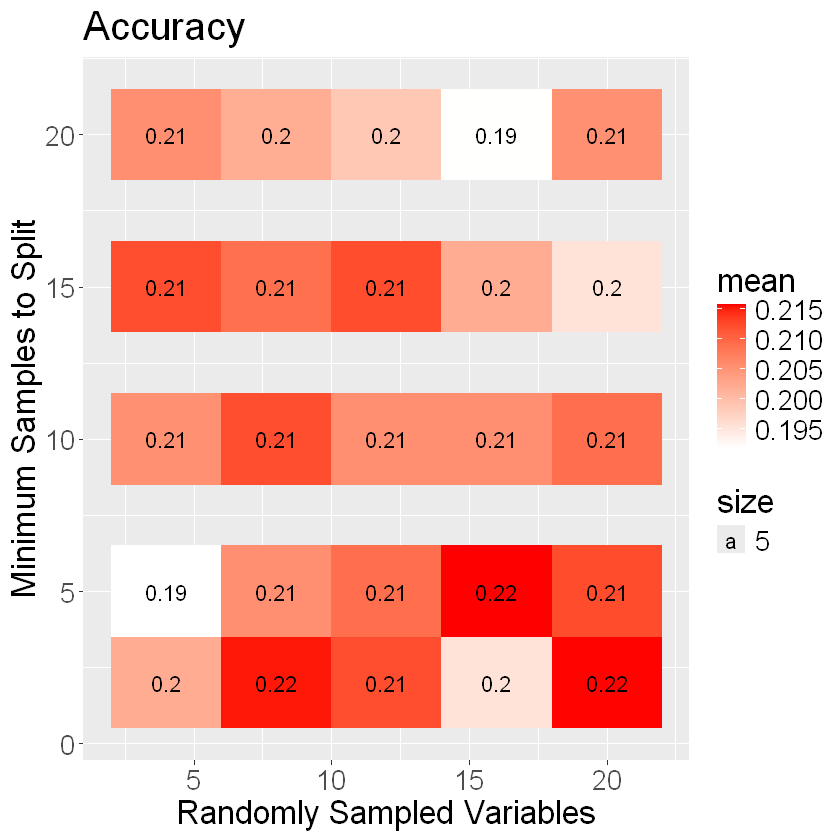

In [11]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters: (mtry, min_n)")
print(best_params)

Ignoring unknown labels:
• colour : "Estimated Recall"


[1] "Best hyperparameters:"
15 
20 


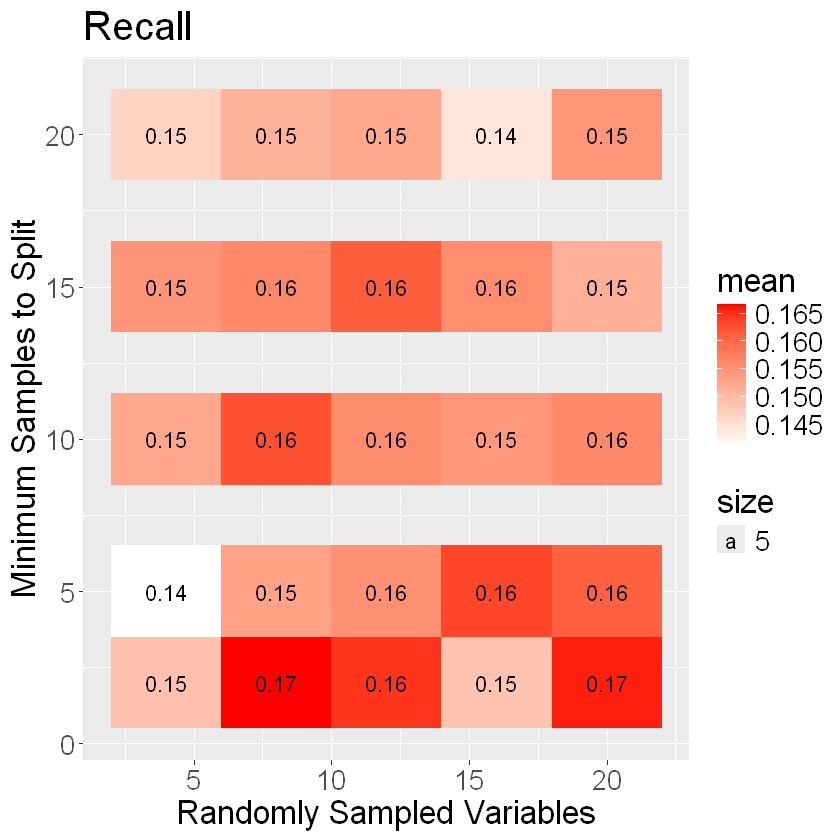

In [12]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "recall")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Recall", title="Recall") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters:")
print(best_params)

In [13]:
# retrain model on best parameters
best_params <- model_tuning %>%
  select_best()
print("Best Parameters:")
print(best_params)

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%
    finalize_workflow(best_params) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    16     5 pre0_mod17_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 115, 119, 120."
Warning message:
"! 16 columns were requested but there were 12 predictors in the data.
ℹ 12 predictors will be used."


══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: rand_forest()

── Preprocessor ────────────────────────────────────────────────────────────────
2 Recipe Steps

• step_scale()
• step_center()

── Model ───────────────────────────────────────────────────────────────────────
Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, mtry = min_cols(~16,      x), num.trees = ~1000, min.node.size = min_rows(~5, x), importance = ~"impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  1000 
Sample size:                      297 
Number of independent variables:  12 
Mtry:                             12 
Target node size:                 5 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.7543456 

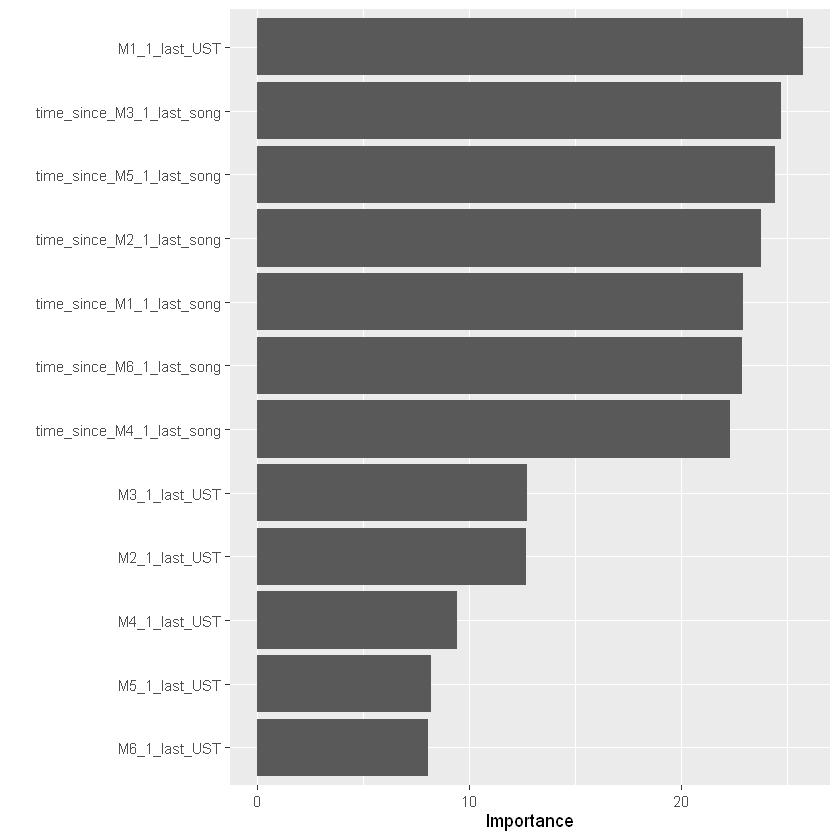

In [14]:
model %>% extract_fit_engine() %>% vip(num_features=50)

In [15]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [16]:
# test_predictions

In [17]:
# What was the accuracy, precision, and recall of our model?
test_predictions %>% metrics(truth = UST, estimate = .pred_class)
test_predictions %>% precision(truth = UST, estimate = .pred_class, event_level = "multiclass") # Precision = correct positive predictions / total positive predictions
test_predictions %>% recall(truth = UST, estimate = .pred_class, event_level = "multiclass") # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.16793893
kap,multiclass,0.03271914


Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'0': 0, '12': 1, '16': 0, '20': 0, '115': 0, '116': 1, '118': 0, '119': 1,
'120': 0"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
precision,macro,0.2280468


Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'0': 0, '16': 0, '20': 0, '115': 0, '118': 0, '120': 0"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
recall,macro,0.167674


In [18]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
confusion_matrix

          Truth
Prediction 0 3 5 8 9 10 12 13 16 17 20 21 29 115 116 117 118 119 120
       0   0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       3   0 5 1 4 8  3  0  1  0  2  0  0  4   0   0   0   0   0   0
       5   0 0 0 1 0  0  0  1  0  0  0  0  1   0   0   0   0   0   0
       8   0 6 2 4 5  3  1  1  0  2  0  0  3   0   0   0   0   0   0
       9   0 5 4 6 5  3  0  1  0  0  0  1  4   0   0   0   0   1   0
       10  0 2 1 3 4  2  0  0  0  1  0  4  2   0   0   0   0   0   0
       12  0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       13  0 0 0 0 0  2  0  0  0  0  0  1  2   0   0   0   0   0   0
       16  0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       17  0 0 0 0 0  0  0  1  0  0  0  0  0   0   0   0   0   0   0
       20  0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       21  0 1 1 2 1  2  0  0  0  0  0  2  1   0   1   0   0   0   0
       29  0 2 0 0 1  0  0  0  0  0  0  0  3   0   0   0   0   0   0
       115 0 0 0 0